# F1 Race Pace Analyzer 🏎️

Analyze Formula 1 race data using FastF1.

## Objectives
- Load race session data
- Compare two drivers' lap times
- Calculate average lap pace
- Visualize race pace using Matplotlib

In [2]:
import fastf1
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path("f1_cache").mkdir(parents=True, exist_ok=True)
Path("output").mkdir(parents=True, exist_ok=True)
fastf1.Cache.enable_cache("f1_cache")

print("Libraries loaded successfully!")
print("FastF1 cache enabled!")

Libraries loaded successfully!
FastF1 cache enabled!


In [15]:
# IMPORTING THE SESSION

YEAR = 2024
GRAND_PRIX = "Monza"

session = fastf1.get_session(YEAR, GRAND_PRIX, "R")

session.load(
    laps=True,
    telemetry=False,
    weather=False,
    messages=False,
)

laps = session.laps

print(f"Loaded {GRAND_PRIX} Grand Prix {YEAR}")
print(f"Total lap records: {len(laps)}")

core           INFO 	Loading data for Italian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core           INFO 	Finished loading data for 20 drivers: ['16', '81', '4', '55', '44', '1', '63', '11', '23', '20', '14', '43', '3', '31', '10', '77', '27', '24', '18', '22']


Loaded Monza Grand Prix 2024
Total lap records: 1008


In [14]:
laps[
    ["Driver", "LapNumber", "LapTime", "Compound"]
].head(10)

,Driver,LapNumber,LapTime,Compound
0,LEC,1.0,0 days 00:01:28.179000,MEDIUM
1,LEC,2.0,0 days 00:01:25.396000,MEDIUM
2,LEC,3.0,0 days 00:01:25.179000,MEDIUM
3,LEC,4.0,0 days 00:01:24.810000,MEDIUM
4,LEC,5.0,0 days 00:01:24.603000,MEDIUM
5,LEC,6.0,0 days 00:01:24.663000,MEDIUM
6,LEC,7.0,0 days 00:01:24.434000,MEDIUM
7,LEC,8.0,0 days 00:01:24.569000,MEDIUM
8,LEC,9.0,0 days 00:01:24.362000,MEDIUM
9,LEC,10.0,0 days 00:01:24.432000,MEDIUM


In [17]:
# COMPARING TWO DRIVERS

DRIVER_1 = "VER"
DRIVER_2 = "LEC"

def get_driver_laps(driver):
    data = laps.pick_drivers([driver]).pick_quicklaps().copy()

    data["LapTimeSeconds"] = (
        data["LapTime"].dt.total_seconds()
    )

    return data

ver_laps = get_driver_laps(DRIVER_1)
lec_laps = get_driver_laps(DRIVER_2)

comparison = pd.DataFrame({
    DRIVER_1: [ver_laps["LapTimeSeconds"].mean()],
    DRIVER_2: [lec_laps["LapTimeSeconds"].mean()],
}, index=["Average lap time (seconds)"])

comparison

,VER,LEC
Average lap time (seconds),84.124375,84.032294


In [9]:
# DISPLAY FASTER AVG

avg_ver = ver_laps["LapTimeSeconds"].mean()
avg_lec = lec_laps["LapTimeSeconds"].mean()

if avg_ver < avg_lec:
    print(f"{DRIVER_1} was faster by {avg_lec - avg_ver:.3f}s per lap")
elif avg_lec < avg_ver:
    print(f"{DRIVER_2} was faster by {avg_ver - avg_lec:.3f}s per lap")
else:
    print("Both drivers had equal average lap times.")

LEC was faster by 0.092s per lap


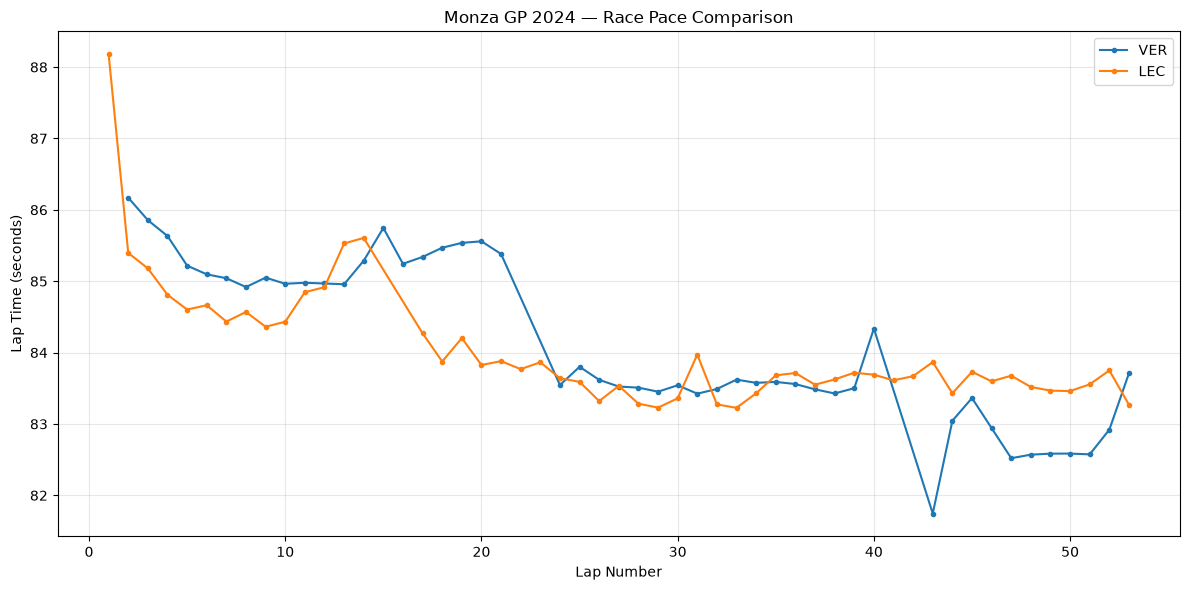

In [ ]:
# PLOT RACE PACE


plt.figure(figsize=(12, 6))

plt.plot(
    ver_laps["LapNumber"],
    ver_laps["LapTimeSeconds"],
    marker="o",
    markersize=3,
    label=DRIVER_1,
)

plt.plot(
    lec_laps["LapNumber"],
    lec_laps["LapTimeSeconds"],
    marker="o",
    markersize=3,
    label=DRIVER_2,
)

plt.title(f"{GRAND_PRIX} GP {YEAR} — Race Pace Comparison")
plt.xlabel("Lap Number")
plt.ylabel("Lap Time (seconds)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    f"output/{YEAR}_{DRIVER_1}_{DRIVER_2}_pace.png",
    dpi=150,
)

plt.show()